# Laboratorio 03 · Visualización de campo tensorial
**De una matriz por punto a autovalores, FA y glifos**

Universidad Nacional del Altiplano – Puno · Escuela Profesional de Ingeniería de Sistemas · Visualización de Datos  
Estudiante: Franco Abondanshieri Arela Mamani · 25 de noviembre de 2026  
Repositorio: https://github.com/Abondanshieri/vd-lab03-campo-tensorial

## 1. Propósito y comprensión del dato

El laboratorio tuvo como propósito reconocer que cada punto contiene una matriz 3 × 3, comprender intuitivamente sus autovalores y autovectores y representar un campo tensorial mediante mapas y elipses.

El campo vivió sobre una grilla de posiciones 2D, pero en cada posición se almacenó una **matriz 3 × 3**. Los autovectores son direcciones especiales de la matriz y los autovalores, los factores asociados a esas direcciones. A partir de los autovalores se calcularon dos resúmenes escalares: la difusividad media (MD), que es su promedio, y la anisotropía fraccional (FA), que mide su diferencia relativa para tensores de difusión positivos. Los datos son sintéticos y no describen esfuerzos ni difusión reales.

## 2. Entorno de ejecución

El cuaderno se ejecutó de forma local con un kernel de Jupyter (Python 3.12) usando exactamente el código de la guía, que solo depende de NumPy y Matplotlib y, por tanto, corre igual en Google Colab. Cada bloque numerado ocupó una celda propia y los bloques se ejecutaron en orden, porque los posteriores reutilizan variables de los anteriores (en particular `w` y `v`, los autovalores y autovectores de todo el campo). La celda siguiente solo registró las versiones empleadas.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110          # nitidez de las figuras exportadas
print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python    : 3.12.10
NumPy     : 2.4.6
Matplotlib: 3.11.2


## 3. Actividades guiadas

### Bloque 1. Conocer una sola matriz antes de crear un campo

**Qué se hizo.** Antes de construir un campo se examinó una única matriz de 3 × 3, para no confundir sus 9 componentes con las 3 direcciones y los 3 valores principales que luego se extraerían. La matriz elegida es diagonal y simétrica, con 3, 1,5 y 0,5 en la diagonal.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Una matriz tensorial simétrica de 3 x 3
A = np.array([[3.0, 0.0, 0.0],
              [0.0, 1.5, 0.0],
              [0.0, 0.0, 0.5]])

print("Matriz A:")
print(A)
print("Dimensiones de A:", A.shape)
print("Componente X-X:", A[0, 0])

Matriz A:
[[3.  0.  0. ]
 [0.  1.5 0. ]
 [0.  0.  0.5]]
Dimensiones de A: (3, 3)
Componente X-X: 3.0


**Resultado observado.** Se imprimió una matriz de 3 filas y 3 columnas con forma `(3, 3)` y componente X-X igual a 3,0. Los nueve números describen cómo responde cada dirección a cada otra; al ser simétrica, solo seis son independientes. Son datos de demostración, no esfuerzos físicos reales.

**Comprobación del aprendizaje.** El resultado representa un tensor de segundo orden en una posición, y la variable que lo controla es la matriz `A`, cuya diagonal fija la intensidad en cada eje.

### Bloque 2. Obtener los autovalores y autovectores

**Qué se hizo.** Con `np.linalg.eigh`, indicada para matrices simétricas, se obtuvieron los autovalores y autovectores de A, se ordenaron de mayor a menor y se verificó la definición `A·e = λ·e` para el primer par. Se eligió una matriz diagonal precisamente para poder comprobar el resultado a simple vista: sus direcciones principales coinciden con los ejes.

In [3]:
valores, vectores = np.linalg.eigh(A)

# Ordenamos de mayor a menor valor
valores = valores[::-1]
vectores = vectores[:, ::-1]

print("Autovalores (mayor a menor):", valores)
print("Autovectores (columnas):")
print(vectores)

# Comprobamos la definición para el primer par
print("¿A·e1 = lambda1·e1?",
      np.allclose(A @ vectores[:, 0], valores[0] * vectores[:, 0]))

Autovalores (mayor a menor): [3.  1.5 0.5]
Autovectores (columnas):
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
¿A·e1 = lambda1·e1? True


**Resultado observado.** Los autovalores resultaron 3,0; 1,5 y 0,5, y los autovectores formaron la matriz identidad: el mayor autovalor (3) correspondió al eje X, el intermedio al eje Y y el menor al eje Z. La comprobación devolvió `True`. `eigh` entrega los autovalores en orden ascendente, por lo que fue necesario invertir tanto el vector de valores como las *columnas* de los vectores para mantener el emparejamiento.

**Comprobación del aprendizaje.** El resultado representa las tres direcciones principales de la matriz con sus factores de estiramiento, y la variable que lo controla es la diagonal de `A`.

### Bloque 3. Comparar isotropía y anisotropía

**Qué se hizo.** Se calculó la anisotropía fraccional (FA) de tres conjuntos de autovalores: tres iguales, tres distintos y uno solo no nulo. Cuando los tres valores principales coinciden el tensor es isotrópico; cuanto más difieren, más anisotrópico. La FA resume esa diferencia relativa entre 0 y 1.

In [4]:
# Tres ejemplos con autovalores positivos
casos = np.array([[2.0, 2.0, 2.0],
                  [3.0, 1.5, 0.5],
                  [4.0, 0.0, 0.0]])

for w in casos:
    md = np.mean(w)                     # Promedio de autovalores
    numerador = np.sum((w - md)**2)     # Diferencias respecto al promedio
    denominador = np.sum(w**2)         # Normalización
    fa = np.sqrt(1.5 * numerador / denominador)
    print("Autovalores:", w, "MD:", round(md, 3),
          "FA:", round(fa, 3))

Autovalores: [2. 2. 2.] MD: 2.0 FA: 0.0
Autovalores: [3.  1.5 0.5] MD: 1.667 FA: 0.643
Autovalores: [4. 0. 0.] MD: 1.333 FA: 1.0


**Resultado observado.** Se obtuvieron FA = 0 para [2, 2, 2], FA = 0,643 para [3, 1,5; 0,5] y FA = 1 para [4, 0, 0], con MD de 2, 1,667 y 1,333. El primero es una esfera (igual difusión en todas las direcciones), el segundo un elipsoide y el tercero el límite ideal de una línea. El factor 1,5 dentro de la raíz normaliza la fórmula para que el máximo teórico sea exactamente 1. La variable `w` de este bucle es solo local de este bloque; más adelante `w` pasará a designar los autovalores de todo el campo.

**Comprobación del aprendizaje.** El resultado representa el grado de anisotropía de tres tensores, y la variable que lo controla es la dispersión de los autovalores respecto de su promedio.

### Bloque 4. Construir una matriz 3 × 3 en cada punto

**Qué se hizo.** Se construyó el campo: una grilla de 15 × 15 posiciones sobre [−2, 2] y, en cada una, un tensor simétrico cuya dirección principal gira con la posición (tangente a circunferencias alrededor del origen) y cuyo autovalor mayor se refuerza en un anillo de radio 1,2. Los otros dos autovalores se fijaron en 1 y 0,6.

In [5]:
# Creamos 15 x 15 posiciones
x = np.linspace(-2, 2, 15)
y = np.linspace(-2, 2, 15)
X, Y = np.meshgrid(x, y)

# La dirección principal gira según la posición
angulo = np.arctan2(Y, X) + np.pi / 2
c = np.cos(angulo)
s = np.sin(angulo)
r = np.sqrt(X**2 + Y**2)

# Valores positivos para el tensor de ejemplo
mayor = 1 + 2 * np.exp(-((r - 1.2)**2) / 0.25)
medio = np.ones_like(X)
menor = 0.6 * np.ones_like(X)

# Reservamos una matriz 3 x 3 para cada posición
T = np.zeros((15, 15, 3, 3))
T[:, :, 0, 0] = mayor*c*c + medio*s*s
T[:, :, 0, 1] = (mayor - medio)*c*s
T[:, :, 1, 0] = T[:, :, 0, 1]
T[:, :, 1, 1] = mayor*s*s + medio*c*c
T[:, :, 2, 2] = menor

print("Número de matrices:", X.size)
print("Forma de T:", T.shape)
print("Matriz en una posición:")
print(np.round(T[7, 11], 2))

Número de matrices: 225
Forma de T: (15, 15, 3, 3)
Matriz en una posición:
[[1.   0.   0.  ]
 [0.   2.97 0.  ]
 [0.   0.   0.6 ]]


**Resultado observado.** Resultaron 225 matrices y `T.shape = (15, 15, 3, 3)`: los dos primeros ejes son la posición y los dos últimos, la matriz; la grilla sigue siendo 2D. La matriz en `T[7, 11]` —fila 7, y = 0; columna 11, x ≈ 1,14— fue diagonal con valores 1; 2,97 y 0,6: sobre el eje X la dirección principal es vertical (ángulo de 90°) y está casi en el anillo, de ahí el 2,97. Cada bloque 2 × 2 del plano XY se construyó como `R·diag(mayor, medio)·Rᵀ`, una rotación de los ejes principales, y la componente Z quedó desacoplada con valor `menor`.

**Comprobación del aprendizaje.** El resultado representa un tensor 3 × 3 por cada una de las 225 posiciones, y las variables que lo controlan son `angulo` (orientación) y `mayor`, `medio`, `menor` (autovalores).

### Bloque 5. Crear mapas escalares a partir del campo tensorial

**Qué se hizo.** Se calcularon los autovalores de las 225 matrices a la vez (`eigh` admite lotes) y cada matriz se redujo a dos números: MD, el promedio de sus autovalores, y FA. Así el campo tensorial dio lugar a dos campos escalares que pudieron dibujarse con los mapas de colores del primer laboratorio.

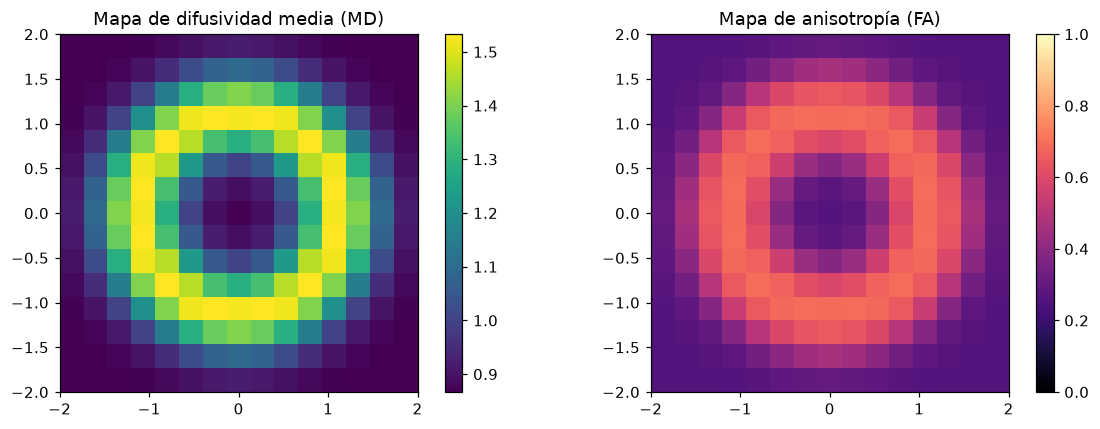

In [6]:
# Obtenemos los tres autovalores en cada punto
w, v = np.linalg.eigh(T)
w = w[:, :, ::-1]
v = v[:, :, :, ::-1]

# MD: promedio de los tres autovalores
MD = np.mean(w, axis=2)

# FA: diferencia relativa de autovalores
numerador = np.sum((w - MD[:, :, None])**2, axis=2)
denominador = np.sum(w**2, axis=2)
FA = np.sqrt(1.5 * numerador / denominador)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im1 = axes[0].imshow(MD, origin="lower", extent=[-2, 2, -2, 2],
                     cmap="viridis")
axes[0].set_title("Mapa de difusividad media (MD)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(FA, origin="lower", extent=[-2, 2, -2, 2],
                     cmap="magma", vmin=0, vmax=1)
axes[1].set_title("Mapa de anisotropía (FA)")
fig.colorbar(im2, ax=axes[1])
plt.tight_layout()
plt.show()

**Resultado observado.** Ambos mapas mostraron un anillo claro de radio ≈ 1,2, donde el autovalor mayor se refuerza hasta 3. El MD varió entre 0,87 en el fondo, (1 + 1 + 0,6)/3, y 1,53 en el anillo, (3 + 1 + 0,6)/3. La FA varió entre 0,26 y 0,69; su mínimo no fue 0 porque el tercer autovalor (0,6) difiere siempre de los otros dos: incluso fuera del anillo el tensor es algo anisotrópico. Al fijarse `vmin = 0` y `vmax = 1` en la FA se vio con honestidad que el anillo está lejos de la anisotropía máxima. Aunque ambos mapas coinciden en forma, no miden lo mismo: MD resume el tamaño medio y FA la desigualdad entre direcciones.

**Comprobación del aprendizaje.** Los gráficos representan dos propiedades escalares derivadas de cada matriz, y las variables que los controlan son los tres autovalores de cada posición.

### Bloque 6. Dibujar glifos: una elipse por posición seleccionada

**Qué se hizo.** Se dibujó una elipse cada dos posiciones de la grilla (submuestreo para evitar solapes). La orientación de cada elipse salió de la proyección al plano XY del autovector principal; su ancho y alto, de los dos mayores autovalores, multiplicados por 0,19 para ajustar el tamaño a la separación entre glifos.

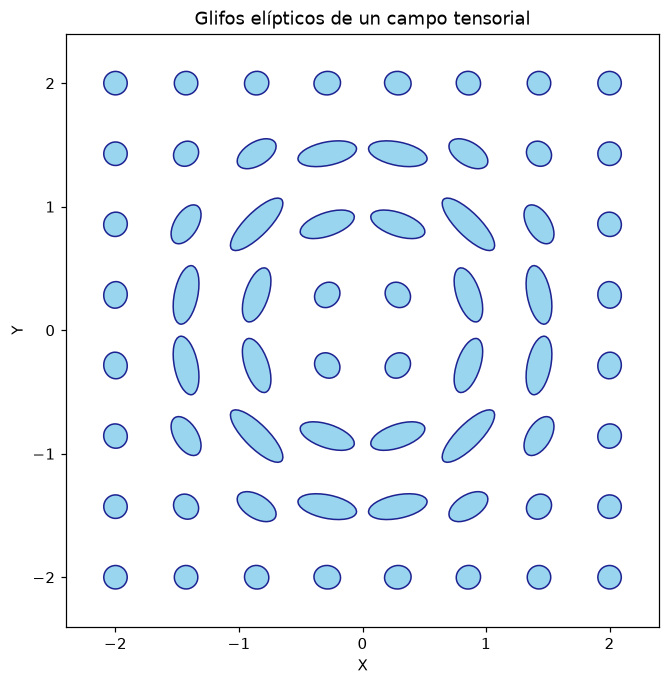

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))

# Dibujamos una elipse cada dos puntos de la grilla
for fila in range(0, 15, 2):
    for columna in range(0, 15, 2):
        # Valores principales de esta matriz
        lam1 = w[fila, columna, 0]
        lam2 = w[fila, columna, 1]

        # Dirección principal proyectada al plano XY
        e1 = v[fila, columna, :, 0]
        ang = np.degrees(np.arctan2(e1[1], e1[0]))

        # Elipses que resumen forma y orientación
        elipse = Ellipse((X[fila, columna], Y[fila, columna]),
                         width=0.19*lam1, height=0.19*lam2,
                         angle=ang, facecolor="skyblue",
                         edgecolor="navy", alpha=0.85)
        ax.add_patch(elipse)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_aspect("equal")
ax.set_title("Glifos elípticos de un campo tensorial")
ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.show()

**Resultado observado.** Se observaron elipses alargadas y tangentes a las circunferencias en el anillo de radio ≈ 1,2 (ancho 0,57 y alto 0,19) y figuras casi circulares en el resto, donde `lam1 ≈ lam2 ≈ 1`. En esas zonas la orientación de la elipse prácticamente carece de significado visual, porque un círculo no tiene eje. Son glifos 2D de un campo de matrices 3 × 3: no representan el tensor completo en volumen, ya que el tercer autovalor y la componente en Z no se dibujan.

**Comprobación del aprendizaje.** El gráfico representa la orientación y la forma de cada tensor submuestreado, y las variables que lo controlan son el autovector principal (ángulo) y los dos mayores autovalores (ejes).

## 4. Retos resueltos individualmente

### Reto 1. Caso isotrópico: [3, 1,5, 0,5] por [2, 2, 2]

**Enunciado.** En el bloque 3 reemplazar el segundo conjunto `[3, 1.5, 0.5]` por `[2, 2, 2]`, comparar FA y explicar qué significa.

In [8]:
def fa_de(lambdas):
    """FA y MD de un conjunto de tres autovalores (misma fórmula del bloque 3)."""
    lambdas = np.asarray(lambdas, dtype=float)
    md = lambdas.mean()
    return md, np.sqrt(1.5 * np.sum((lambdas - md)**2) / np.sum(lambdas**2))

original = [[2, 2, 2], [3, 1.5, 0.5], [4, 0, 0]]
nuevo    = [[2, 2, 2], [2, 2, 2],     [4, 0, 0]]

print(f"{'Autovalores':<18}{'MD':>8}{'FA antes':>10}{'FA ahora':>10}")
for a, b in zip(original, nuevo):
    print(f"{str(b):<18}{fa_de(b)[0]:>8.3f}{fa_de(a)[1]:>10.3f}{fa_de(b)[1]:>10.3f}")

# Un tensor isotrópico es un múltiplo de la identidad: toda dirección es autovector
I2 = 2 * np.eye(3)
print("\nAutovalores de 2·I:", np.linalg.eigvalsh(I2))
print("Con un vector cualquiera p:", np.allclose(I2 @ np.array([1.0, 2.0, 3.0]), 2 * np.array([1.0, 2.0, 3.0])))

Autovalores             MD  FA antes  FA ahora
[2, 2, 2]            2.000     0.000     0.000
[2, 2, 2]            2.000     0.643     0.000
[4, 0, 0]            1.333     1.000     1.000

Autovalores de 2·I: [2. 2. 2.]
Con un vector cualquiera p: True


**Análisis.** Al sustituir el conjunto intermedio por [2, 2, 2] su FA bajó de 0,643 a 0: el numerador de la fórmula, la suma de las diferencias respecto al promedio, se anula cuando los tres autovalores son iguales. Un tensor así es un múltiplo de la identidad (`2·I`) y representa una **esfera**: se comporta igual en todas las direcciones. Por eso no tiene direcciones privilegiadas —cualquier vector es autovector, como confirmó la última línea— y el glifo correspondiente sería un círculo, sin orientación. El caso del medio dejó de ser «intermedio» y ahora hay dos tensores indistinguibles. Con ello se verificó que la FA mide la forma de la distribución de autovalores y no su magnitud: el tensor [2, 2, 2] es «grande» (MD = 2) y a la vez totalmente isótropo.

### Reto 2. Reforzar la anisotropía: el 2 de `mayor` por 3

**Enunciado.** En el bloque 4 cambiar el 2 de `mayor = 1 + 2·...` por 3, volver a ejecutar los bloques 4, 5 y 6 y explicar cómo cambian MD, FA y las elipses.

¿amp=2 reproduce el bloque 5? True
amp=2: MD 0.87-1.53 | FA 0.26-0.69 | autovalor mayor máx. 3.00 | ancho máx. de elipse 0.57
amp=3: MD 0.87-1.87 | FA 0.26-0.77 | autovalor mayor máx. 4.00 | ancho máx. de elipse 0.76
Separación entre elipses dibujadas (paso 2): 0.571


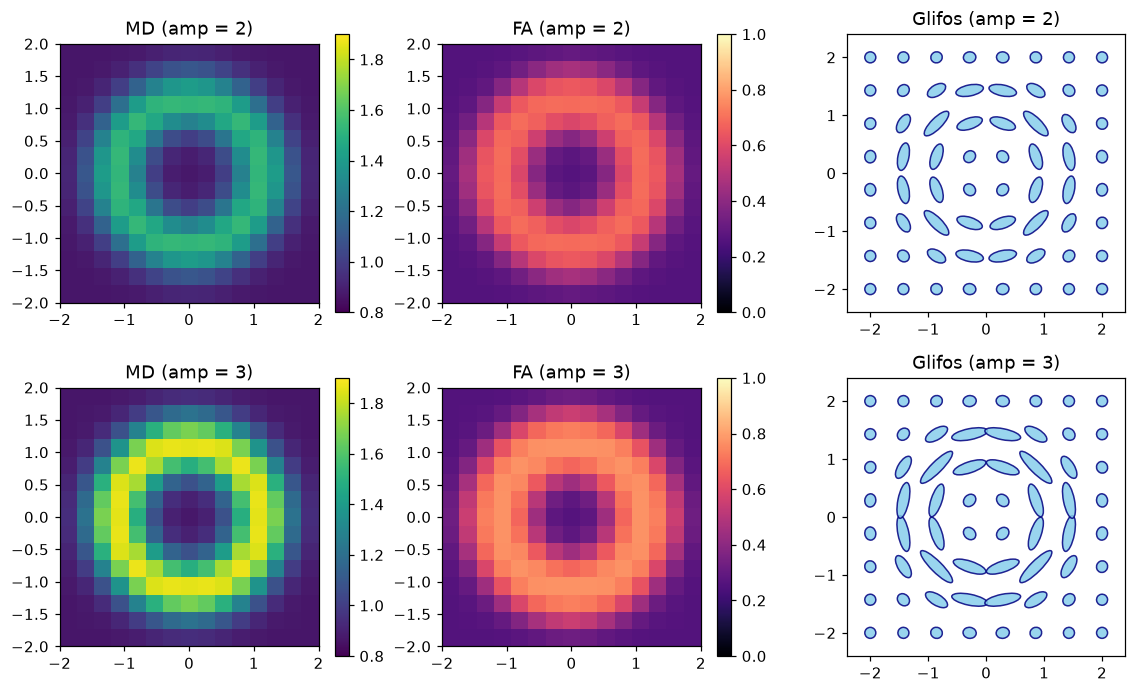

In [9]:
def campo_tensorial(amp):
    """Repite los bloques 4 y 5 con amplitud `amp` en el anillo; devuelve autovalores, autovectores, MD y FA."""
    angulo = np.arctan2(Y, X) + np.pi / 2
    cc, ss = np.cos(angulo), np.sin(angulo)
    rr = np.sqrt(X**2 + Y**2)
    mayor_ = 1 + amp * np.exp(-((rr - 1.2)**2) / 0.25)
    medio_, menor_ = np.ones_like(X), 0.6 * np.ones_like(X)
    Tt = np.zeros((15, 15, 3, 3))
    Tt[:, :, 0, 0] = mayor_*cc*cc + medio_*ss*ss
    Tt[:, :, 0, 1] = (mayor_ - medio_)*cc*ss
    Tt[:, :, 1, 0] = Tt[:, :, 0, 1]
    Tt[:, :, 1, 1] = mayor_*ss*ss + medio_*cc*cc
    Tt[:, :, 2, 2] = menor_
    ww, vv = np.linalg.eigh(Tt)
    ww, vv = ww[:, :, ::-1], vv[:, :, :, ::-1]
    md = ww.mean(axis=2)
    fa = np.sqrt(1.5 * np.sum((ww - md[:, :, None])**2, axis=2) / np.sum(ww**2, axis=2))
    return ww, vv, md, fa

def glifos(ax, ww, vv, paso=2):
    """Repite el bloque 6 sobre un eje dado."""
    for fila in range(0, 15, paso):
        for columna in range(0, 15, paso):
            e1 = vv[fila, columna, :, 0]
            ang = np.degrees(np.arctan2(e1[1], e1[0]))
            ax.add_patch(Ellipse((X[fila, columna], Y[fila, columna]),
                                 width=0.19*ww[fila, columna, 0], height=0.19*ww[fila, columna, 1],
                                 angle=ang, facecolor="skyblue", edgecolor="navy", alpha=0.85))
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4); ax.set_aspect("equal")

# Control: con amp = 2 se debe reproducir el campo del bloque 5
w2, v2, MD2, FA2 = campo_tensorial(2)
print("¿amp=2 reproduce el bloque 5?", np.allclose(MD2, MD) and np.allclose(FA2, FA))

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4))
for fila, amp in enumerate([2, 3]):
    ww, vv, md, fa = campo_tensorial(amp)
    print(f"amp={amp}: MD {md.min():.2f}-{md.max():.2f} | FA {fa.min():.2f}-{fa.max():.2f} | "
          f"autovalor mayor máx. {ww[:, :, 0].max():.2f} | ancho máx. de elipse {0.19*ww[:, :, 0].max():.2f}")
    i1 = axes[fila, 0].imshow(md, origin="lower", extent=[-2, 2, -2, 2], cmap="viridis", vmin=0.8, vmax=1.9)
    axes[fila, 0].set_title(f"MD (amp = {amp})")
    fig.colorbar(i1, ax=axes[fila, 0])
    i2 = axes[fila, 1].imshow(fa, origin="lower", extent=[-2, 2, -2, 2], cmap="magma", vmin=0, vmax=1)
    axes[fila, 1].set_title(f"FA (amp = {amp})")
    fig.colorbar(i2, ax=axes[fila, 1])
    glifos(axes[fila, 2], ww, vv)
    axes[fila, 2].set_title(f"Glifos (amp = {amp})")
print("Separación entre elipses dibujadas (paso 2):", round(8 / 14, 3))
plt.tight_layout()
plt.show()

**Análisis.** Subir el 2 a 3 elevó el autovalor mayor en el anillo de 3 a 4 y dejó intacto todo lo demás, y la consola lo reflejó: el MD máximo pasó de 1,53 a 1,87 (su mínimo siguió en 0,87), la FA máxima de 0,69 a 0,77 (su mínimo siguió en 0,26) y el ancho máximo de las elipses de 0,57 a 0,76. Como el control con `amp = 2` reprodujo exactamente el campo del bloque 5, la comparación fue limpia. En los mapas, el anillo se hizo más brillante y la diferencia con el fondo, más marcada. En los glifos ocurrió algo importante: con 0,76 de ancho, las elipses del anillo **superaron** la separación de 0,571 entre elipses dibujadas y empezaron a solaparse incluso con paso 2. Es decir, un cambio puramente de datos puede arruinar un glifo cuyo tamaño estaba calibrado (el 0,19) para otro rango. Esa escala se debe recalcular o normalizar con el valor máximo del campo.

### Reto 3. Paso del bucle de glifos de 2 a 1

**Enunciado.** En el bloque 6 cambiar el paso del bucle de 2 a 1 y explicar por qué algunas elipses pueden superponerse.

Paso 2: separación = 0.571 | ancho máx. = 0.57 | elipses más anchas que la separación: 0 de 64
Paso 1: separación = 0.286 | ancho máx. = 0.57 | elipses más anchas que la separación: 108 de 225


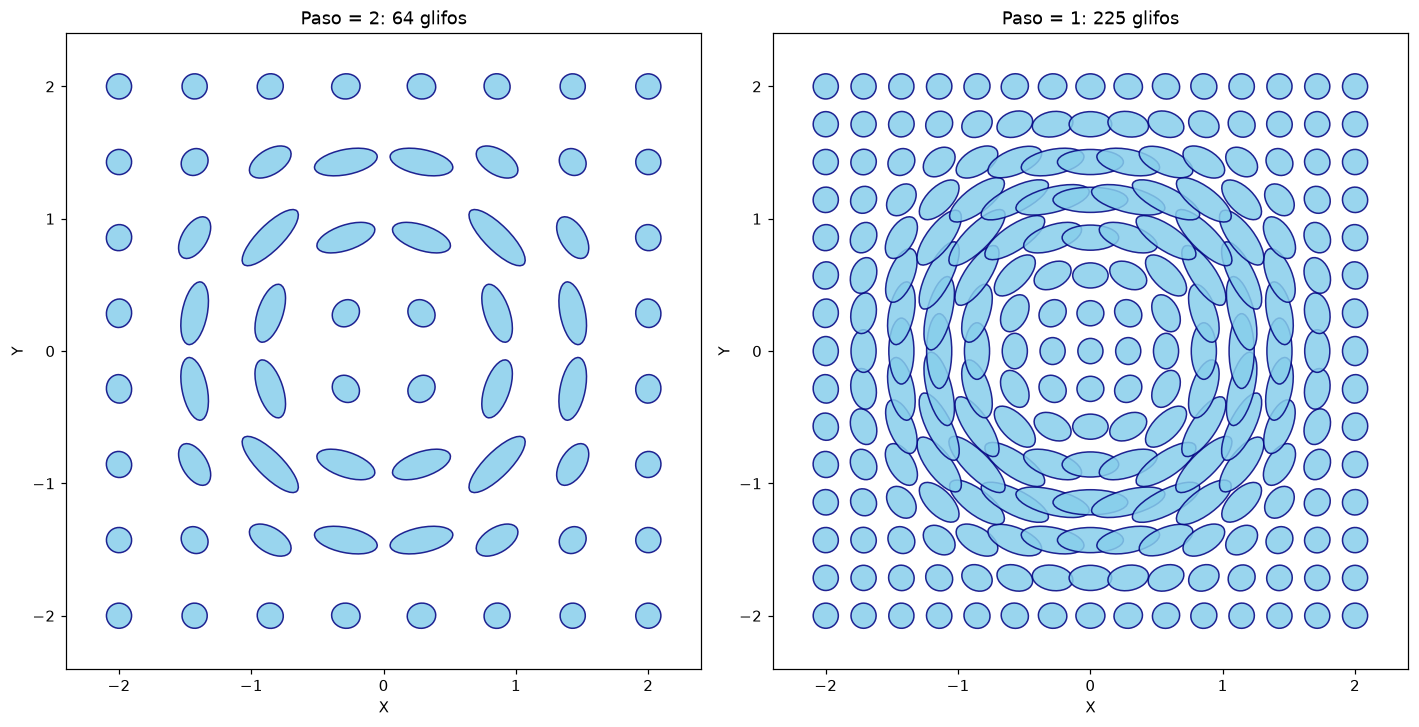

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, paso in zip(axes, [2, 1]):
    glifos(ax, w, v, paso=paso)                 # w, v: campo original del bloque 5
    ax.set_title(f"Paso = {paso}: {len(range(0, 15, paso))**2} glifos")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

for paso in (2, 1):
    separacion = paso * 4 / 14                   # distancia entre posiciones dibujadas
    anchos = 0.19 * w[::paso, ::paso, 0]         # ancho de cada elipse
    print(f"Paso {paso}: separación = {separacion:.3f} | ancho máx. = {anchos.max():.2f} | "
          f"elipses más anchas que la separación: {int((anchos > separacion).sum())} de {anchos.size}")
plt.tight_layout()
plt.show()

**Análisis.** Con paso 1 se dibujaron los 225 glifos y la separación entre centros bajó de 0,571 a 0,286, mientras que el tamaño de cada elipse no cambió (ancho máximo 0,57). Como criterio simple, una elipse **más ancha que la separación** invade a su vecina: con paso 2 ninguna lo hace (0 de 64; las del anillo apenas se rozan, 0,57 frente a 0,571), pero con paso 1 lo hacen 108 de 225. Por eso en el anillo las elipses se montan unas sobre otras y la figura se vuelve una franja azul donde ya no se distingue cada glifo, aunque en las zonas casi circulares (ancho 0,19) hay holgura. El submuestreo de la guía es, entonces, una decisión de diseño: se sacrifica cantidad de posiciones para conservar la legibilidad de cada glifo.

## 5. Preguntas de interpretación

**1. ¿Por qué una celda de este ejemplo tiene una matriz de 3 × 3?**  
Porque el dato que modela el ejemplo es un tensor de segundo orden en el espacio 3D: relaciona cada una de las 3 direcciones con cada una de las 3, lo que da 9 componentes (6 independientes al ser simétrico). La grilla solo fija *dónde* está definido, y es 2D por simplicidad de dibujo.

**2. ¿Qué diferencia hay entre una grilla 2D y una matriz 3 × 3 dentro de cada celda?**  
La grilla es el dominio —las 225 posiciones ordenadas en 15 filas y 15 columnas—; la matriz es el valor guardado en cada posición. En `T.shape = (15, 15, 3, 3)`, los dos primeros ejes indexan el lugar y los dos últimos, el contenido.

**3. ¿Qué indican los autovectores y qué indican los autovalores?**  
Los autovectores son las direcciones que la matriz no gira, solo estira o comprime (las direcciones principales); los autovalores son los factores de ese estiramiento. En un tensor de difusión, el autovector principal marca la dirección de máxima difusión y su autovalor, cuánta hay.

**4. ¿Qué sucede con FA cuando los tres autovalores son iguales?**  
Vale 0: el numerador (diferencias respecto al promedio) se anula. El tensor es isotrópico —una esfera— y no tiene direcciones privilegiadas, como mostró el Reto 1.

**5. ¿Cómo es posible obtener un mapa de colores escalar desde un campo tensorial?**  
Reduciendo cada matriz a un número que la resuma, como MD (promedio de autovalores) o FA (su dispersión relativa). Cada resumen es un campo escalar sobre la misma grilla y se dibuja como en el primer laboratorio, a costa de perder la orientación.

**6. ¿Qué información aportan las elipses y qué información no muestran?**  
Aportan la orientación del autovector principal en el plano XY y la forma relativa de los dos mayores autovalores. No muestran el tercer autovalor, la componente en Z, los nueve valores originales ni una escala absoluta (el 0,19 es arbitrario); y donde `lam1 ≈ lam2` la orientación carece de sentido. Son un resumen 2D, no el tensor 3D.

## 6. Conclusiones

1. Un campo tensorial asocia una matriz a cada punto del espacio, de modo que la posición (2D) y el contenido (3 × 3) son cosas distintas, y el dato completo tiene forma `(15, 15, 3, 3)`. Aprendí que una matriz simétrica se entiende mejor a través de sus autovalores y autovectores —tamaños y direcciones principales— y que de ellos se obtienen escalares con significado, como MD (tamaño medio) y FA (desigualdad entre direcciones, de 0 a 1), que no dependen de la orientación de los ejes.

2. Interpreto los gráficos como resúmenes, cada uno con su pérdida: MD y FA permiten usar mapas de color pero descartan la orientación, y los glifos elípticos conservan la orientación pero omiten el tercer autovalor y dependen de una escala arbitraria que puede producir solapes (Retos 2 y 3). Mirarlos juntos y con la escala de color fija, por ejemplo con la FA entre 0 y 1, evita sacar conclusiones exageradas: el anillo parecía muy anisotrópico, pero su FA máxima fue 0,69.